In [1]:
import pandas as pd
dataset = pd.read_csv("insurance_pre.csv")

In [2]:
dataset

,age,sex,bmi,children,smoker,charges
0,19,female,27.900,0,yes,16884.92400
1,18,male,33.770,1,no,1725.55230
2,28,male,33.000,3,no,4449.46200
3,33,male,22.705,0,no,21984.47061
4,32,male,28.880,0,no,3866.85520
...,...,...,...,...,...,...
1333,50,male,30.970,3,no,10600.54830
1334,18,female,31.920,0,no,2205.98080
1335,18,female,36.850,0,no,1629.83350
1336,21,female,25.800,0,no,2007.94500


In [3]:
dataset = pd.get_dummies(dataset,dtype = int)

In [4]:
dataset

,age,bmi,children,charges,sex_female,sex_male,smoker_no,smoker_yes
0,19,27.900,0,16884.92400,1,0,0,1
1,18,33.770,1,1725.55230,0,1,1,0
2,28,33.000,3,4449.46200,0,1,1,0
3,33,22.705,0,21984.47061,0,1,1,0
4,32,28.880,0,3866.85520,0,1,1,0
...,...,...,...,...,...,...,...,...
1333,50,30.970,3,10600.54830,0,1,1,0
1334,18,31.920,0,2205.98080,1,0,1,0
1335,18,36.850,0,1629.83350,1,0,1,0
1336,21,25.800,0,2007.94500,1,0,1,0


In [5]:
dataset.columns

Index(['age', 'bmi', 'children', 'charges', 'sex_female', 'sex_male',
       'smoker_no', 'smoker_yes'],
      dtype='str')

In [6]:
indepentVar = dataset[['age', 'bmi', 'children', 'sex_female', 'sex_male',
       'smoker_no', 'smoker_yes']]

In [7]:
indepentVar

,age,bmi,children,sex_female,sex_male,smoker_no,smoker_yes
0,19,27.900,0,1,0,0,1
1,18,33.770,1,0,1,1,0
2,28,33.000,3,0,1,1,0
3,33,22.705,0,0,1,1,0
4,32,28.880,0,0,1,1,0
...,...,...,...,...,...,...,...
1333,50,30.970,3,0,1,1,0
1334,18,31.920,0,1,0,1,0
1335,18,36.850,0,1,0,1,0
1336,21,25.800,0,1,0,1,0


In [8]:
depententVar = dataset[['charges']]

In [9]:
depententVar

,charges
0,16884.92400
1,1725.55230
2,4449.46200
3,21984.47061
4,3866.85520
...,...
1333,10600.54830
1334,2205.98080
1335,1629.83350
1336,2007.94500


In [10]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(indepentVar,depententVar,test_size=0.30,random_state=0)

In [11]:
from sklearn.tree import DecisionTreeRegressor
regressor = DecisionTreeRegressor(criterion='squared_error', splitter='best')
regressor = regressor.fit(x_train,y_train)

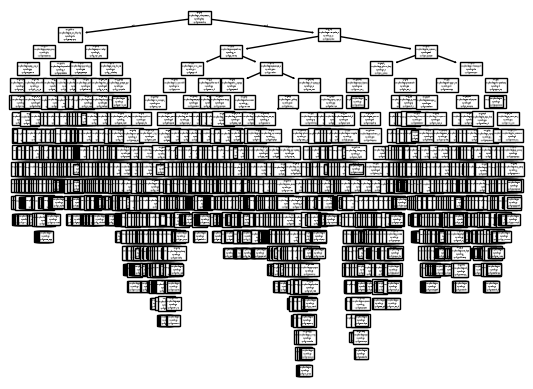

In [16]:
import matplotlib.pyplot as plt
from sklearn import tree
tree.plot_tree(regressor)
plt.show()

In [17]:
y_pred=regressor.predict(x_test)

In [18]:
y_pred

array([10085.846   ,  8930.93455 , 44202.6536  , 13143.86485 ,
        9264.797   , 21984.47061 ,  1615.7667  , 10381.4787  ,
        7954.517   ,  5253.524   ,  4766.022   , 30284.64294 ,
        7633.7206  ,  4992.3764  , 18246.4955  , 11015.1747  ,
       12142.5786  ,  3292.52985 ,  6455.86265 , 33307.5508  ,
       24869.8368  , 11987.1682  ,  9625.92    , 27218.43725 ,
        1261.442   ,  4151.0287  ,  3558.62025 ,  8538.28845 ,
        3353.284   ,  8116.26885 ,  7954.517   , 48673.5588  ,
       13981.85035 , 10594.2257  , 15817.9857  ,  3554.203   ,
        8733.22925 , 44585.45587 , 40941.2854  ,  1880.07    ,
       21984.47061 ,  2866.091   , 21082.16    , 43813.8661  ,
       36307.7983  ,  3056.3881  , 11015.1747  ,  7046.7222  ,
        4719.52405 , 11830.6072  ,  2473.3341  ,  2331.519   ,
       27218.43725 , 60021.39897 , 11856.4115  , 19673.33573 ,
        3021.80915 ,  8442.667   ,  7518.02535 , 12913.9924  ,
        1252.407   , 46130.5265  , 14119.62    , 25333.

In [19]:
from sklearn.metrics import r2_score
r_score = r2_score(y_test,y_pred)

In [20]:
r_score

0.6959771237931038